# Ejercicios del Capítulo 4 — Serie Schaum: *Probabilidad y Estadística*
### Distribuciones especiales de probabilidad

**Estudiante:** Meir Bazurto Montoya
**Código:** 2429893

# Ejercicios a realizar

En el siguiente código Julia cambie `1234` por su código de estudiante y corra la celda. Con el resultado, realice los ejercicios del capítulo 4 de Serie Schaum en este mismo archivo. Escriba los enunciados y *todos* los procedimientos para resolver cada ejercicio. Si es necesario haga las gráficas adecuadas y use los paquetes de Julia que necesite para esto. Guarde este archivo ipynb en su cuenta de github y envíe la dirección al enlace Moodle de esta tarea.

![Schaum](prob.png)

In [1]:
using Random, Distributions
Random.seed!(2429893)

TaskLocalRNG()

In [2]:
sort!(sample([61:94; 98:104; 108:120],15,replace=false,ordered=false))

15-element Vector{Int64}:
  65
  67
  73
  79
  80
  81
  82
  83
  92
  99
 102
 103
 104
 109
 117

En este caso se deben resolver los ejercicios `4.65`, `4.67`, `4.73`, `4.79`, `4.80`, `4.81`, `4.82`, `4.83`, `4.92`, `4.99`, `4.102`, `4.103`, `4.104`, `4.109` y `4.117`.

## Paquetes utilizados

* `Distributions`: distribuciones binomial, normal, Poisson, hipergeométrica, uniforme, $\chi^2$ y $t$ de Student.
* `Plots`: gráficas.
* `Random`: semilla para las simulaciones.

In [3]:
using Plots
gr(fmt = :png)
default(framestyle = :box, legendfontsize = 8, titlefontsize = 11, size = (700, 380))

# Función auxiliar: sombrea el área bajo la densidad de `d` entre `a` y `b`
function sombrear!(p, d, a, b; color = :orange, alpha = 0.5, label = "")
    lo = max(a, mean(d) - 5std(d)); hi = min(b, mean(d) + 5std(d))
    lo >= hi && return p
    xs = range(lo, hi, length = 300)
    plot!(p, xs, pdf.(d, xs); fillrange = 0, fillalpha = alpha, fillcolor = color,
          linealpha = 0, label = label)
end

sombrear! (generic function with 1 method)

---
## Ejercicio 4.65

**Enunciado.** Hallar la probabilidad de obtener una suma de 11 **(a)** una vez, **(b)** dos veces, en dos lanzamientos de un par de dados legales.

**Procedimiento.**

En un lanzamiento de dos dados hay $6 \times 6 = 36$ resultados igualmente probables. La suma 11 se obtiene con $(5,6)$ y $(6,5)$, así que la probabilidad de "éxito" en un lanzamiento es

$$p = \frac{2}{36} = \frac{1}{18}, \qquad q = 1 - p = \frac{17}{18}.$$

Sea $X$ el número de veces que sale 11 en $n = 2$ lanzamientos independientes. Entonces $X \sim \text{Binomial}(n=2,\ p=1/18)$ y

$$P(X = x) = \binom{2}{x} p^x q^{2-x}.$$

**(a)** $$P(X = 1) = \binom{2}{1}\left(\frac{1}{18}\right)\left(\frac{17}{18}\right) = \frac{2 \cdot 17}{324} = \frac{34}{324} = \frac{17}{162} \approx 0.1049$$

**(b)** $$P(X = 2) = \binom{2}{2}\left(\frac{1}{18}\right)^2 = \frac{1}{324} \approx 0.0031$$

In [4]:
p = 2//36                                  # probabilidad exacta de sumar 11
X = Binomial(2, float(p))

a_exacta = binomial(2, 1) * p * (1 - p)    # cálculo exacto con racionales
b_exacta = binomial(2, 2) * p^2

println("p = ", p)
println("(a) P(X = 1) = ", a_exacta, " ≈ ", round(pdf(X, 1), digits = 4))
println("(b) P(X = 2) = ", b_exacta, " ≈ ", round(pdf(X, 2), digits = 4))

p = 1

//18
(a) P(X = 1) = 17//162 ≈ 0.1049


(b) P(X = 2) = 1//324 ≈ 0.0031


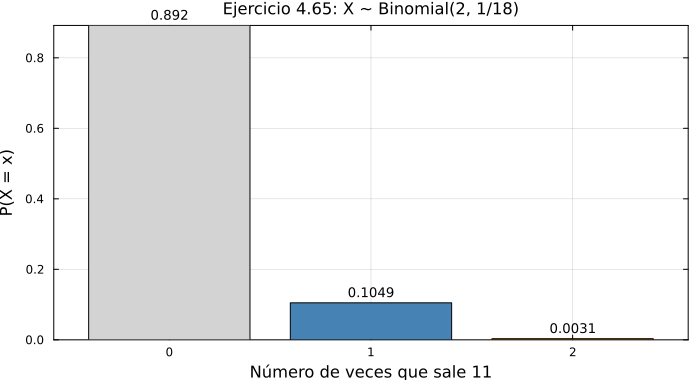

In [5]:
bar(0:2, pdf.(X, 0:2), color = [:lightgray, :steelblue, :darkorange], legend = false,
    xlabel = "Número de veces que sale 11", ylabel = "P(X = x)",
    title = "Ejercicio 4.65: X ~ Binomial(2, 1/18)", xticks = 0:2)
annotate!([(x, pdf(X, x) + 0.03, text(string(round(pdf(X, x), digits = 4)), 9)) for x in 0:2])

**Respuesta:** (a) $17/162 \approx 0.1049$ (b) $1/324 \approx 0.0031$

---
## Ejercicio 4.67

**Enunciado.** Hallar la probabilidad de acertar, adivinando, por lo menos 6 de las 10 respuestas de un examen de falso o verdadero.

**Procedimiento.**

Cada pregunta se acierta al azar con probabilidad $p = 1/2$, de forma independiente. Si $X$ es el número de aciertos en $n = 10$ preguntas, $X \sim \text{Binomial}(10,\ 1/2)$:

$$P(X \ge 6) = \sum_{x=6}^{10} \binom{10}{x}\left(\frac12\right)^{x}\left(\frac12\right)^{10-x} = \frac{1}{2^{10}} \sum_{x=6}^{10}\binom{10}{x}$$

$$\binom{10}{6} = 210,\quad \binom{10}{7} = 120,\quad \binom{10}{8} = 45,\quad \binom{10}{9} = 10,\quad \binom{10}{10} = 1$$

$$P(X \ge 6) = \frac{210 + 120 + 45 + 10 + 1}{1024} = \frac{386}{1024} = \frac{193}{512} \approx 0.3770$$

In [6]:
X = Binomial(10, 0.5)

combinaciones = [binomial(10, x) for x in 6:10]
exacta = sum(combinaciones) // 2^10

println("C(10,x) para x = 6..10: ", combinaciones)
println("P(X ≥ 6) = ", exacta, " ≈ ", round(ccdf(X, 5), digits = 4))

C(10,x) para x = 6..10: 

[210, 120, 45, 10, 1]
P(X ≥ 6) = 193

//512 ≈ 0.377


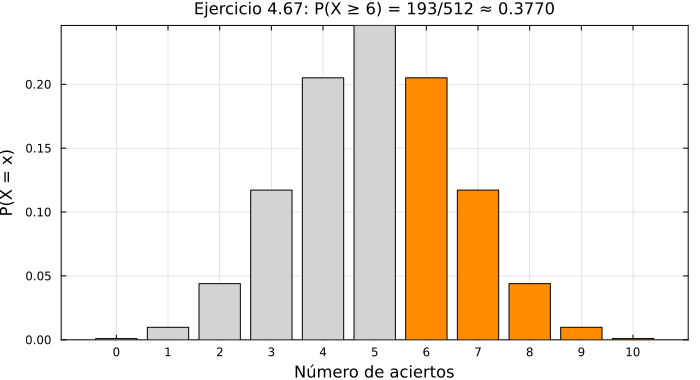

In [7]:
colores = [x >= 6 ? :darkorange : :lightgray for x in 0:10]
bar(0:10, pdf.(X, 0:10), color = colores, legend = false, xticks = 0:10,
    xlabel = "Número de aciertos", ylabel = "P(X = x)",
    title = "Ejercicio 4.67: P(X ≥ 6) = 193/512 ≈ 0.3770")

**Respuesta:** $P(X \ge 6) = 193/512 \approx 0.3770$

---
## Ejercicio 4.73

**Enunciado.** Hallar **(a)** la media y **(b)** la desviación estándar de un examen en el que las notas 70 y 88 corresponden a puntuaciones tipificadas (estándar) de $-0.6$ y $1.4$, respectivamente.

**Procedimiento.**

La puntuación estándar es $z = \dfrac{x - \mu}{\sigma}$, es decir, $x = \mu + z\sigma$. Con los dos datos se plantea el sistema

$$\begin{cases} \mu - 0.6\,\sigma = 70 \\ \mu + 1.4\,\sigma = 88 \end{cases}$$

Restando la primera ecuación de la segunda:

$$2\sigma = 18 \quad\Longrightarrow\quad \sigma = 9$$

Reemplazando en la primera ecuación:

$$\mu = 70 + 0.6(9) = 70 + 5.4 = 75.4$$

In [8]:
# Sistema lineal  A * [μ, σ] = b
A = [1 -0.6;
     1  1.4]
b = [70, 88]
μ, σ = A \ b

println("(a) μ = ", round(μ, digits = 4))
println("(b) σ = ", round(σ, digits = 4))
println("Comprobación: z(70) = ", round((70 - μ)/σ, digits = 4), ",  z(88) = ", round((88 - μ)/σ, digits = 4))

(a) μ = 75.4


(b) σ = 9.0
Comprobación: z(70) = -0.6,  z(88) = 1.4


**Respuesta:** (a) $\mu = 75.4$ (b) $\sigma = 9$

---
## Ejercicio 4.79

**Enunciado.** Si $X$ está normalmente distribuida con media 5 y desviación estándar 2, hallar $P(X > 8)$.

**Procedimiento.**

Se estandariza con $Z = \dfrac{X - \mu}{\sigma}$:

$$P(X > 8) = P\left(Z > \frac{8 - 5}{2}\right) = P(Z > 1.5) = 1 - \Phi(1.5) = 1 - 0.9332 = 0.0668$$

In [9]:
X = Normal(5, 2)
z = (8 - 5) / 2
println("z = ", z)
println("P(X > 8) = 1 - Φ(1.5) = ", round(ccdf(X, 8), digits = 4))

z = 1.5
P(X > 8) = 1 - Φ(1.5) = 0.0668


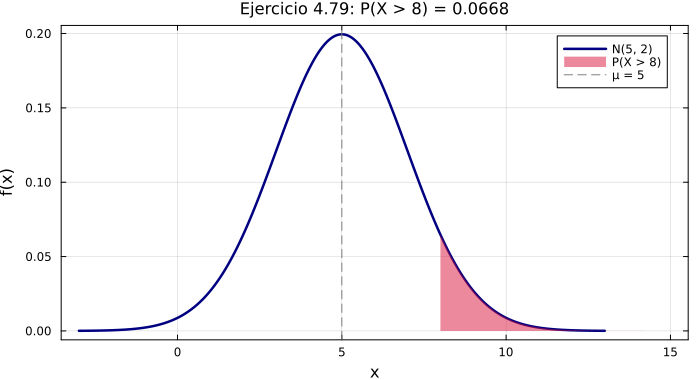

In [10]:
xs = range(-3, 13, length = 500)
p = plot(xs, pdf.(X, xs), lw = 2.5, color = :navy, label = "N(5, 2)",
         xlabel = "x", ylabel = "f(x)", title = "Ejercicio 4.79: P(X > 8) = 0.0668")
sombrear!(p, X, 8, Inf; color = :crimson, label = "P(X > 8)")
vline!([5], ls = :dash, color = :gray, label = "μ = 5")

**Respuesta:** $P(X > 8) \approx 0.0668$

---
## Ejercicio 4.80

**Enunciado.** Las estaturas de 300 estudiantes están normalmente distribuidas con media 68.0 pulgadas y desviación estándar 3.0 pulgadas. ¿Cuántos estudiantes tienen estaturas **(a)** mayores que 72 pulgadas, **(b)** menores o iguales que 64 pulgadas, **(c)** entre 65 y 71 pulgadas inclusive, **(d)** iguales a 68 pulgadas? Suponga que las medidas se registran a la pulgada más cercana.

**Procedimiento.**

Como las estaturas se registran redondeadas a la pulgada más cercana, una estatura registrada como $h$ corresponde realmente al intervalo $(h - 0.5,\ h + 0.5)$. Por eso se aplica una **corrección de 0.5**. Sea $X \sim N(68,\ 3)$.

**(a)** "Mayor que 72" significa registrada como 73 o más, es decir, $X > 72.5$:
$$P(X > 72.5) = P\left(Z > \frac{72.5 - 68}{3}\right) = P(Z > 1.5) = 0.0668 \quad\Rightarrow\quad 300(0.0668) \approx 20$$

**(b)** "Menor o igual que 64" significa $X < 64.5$:
$$P(X < 64.5) = P\left(Z < \frac{64.5 - 68}{3}\right) = P(Z < -1.17) = 0.1210 \quad\Rightarrow\quad 300(0.1210) \approx 36$$

**(c)** "Entre 65 y 71 inclusive" significa $64.5 < X < 71.5$:
$$P(-1.17 < Z < 1.17) = 2\Phi(1.17) - 1 = 2(0.8790) - 1 = 0.7580 \quad\Rightarrow\quad 300(0.7580) \approx 227$$

**(d)** "Igual a 68" significa $67.5 < X < 68.5$:
$$P\left(\frac{67.5 - 68}{3} < Z < \frac{68.5 - 68}{3}\right) = P(-0.17 < Z < 0.17) = 2(0.5675) - 1 = 0.1350 \quad\Rightarrow\quad 300(0.1350) \approx 40$$

In [11]:
X = Normal(68, 3)
N = 300

pa = ccdf(X, 72.5)
pb = cdf(X, 64.5)
pc = cdf(X, 71.5) - cdf(X, 64.5)
pd = cdf(X, 68.5) - cdf(X, 67.5)

for (letra, prob) in zip(["(a)", "(b)", "(c)", "(d)"], [pa, pb, pc, pd])
    println(letra, "  P = ", round(prob, digits = 4), "   →  ", round(N * prob, digits = 2),
            " ≈ ", round(Int, N * prob), " estudiantes")
end

(a)  P = 0.0668   →  20.04 ≈ 20 estudiantes
(b)  P = 0.1217   →  36.5 ≈ 37 estudiantes
(c)  P = 0.7567   →  227.0 ≈ 227 estudiantes
(d)  P = 0.1324   →  39.71 ≈ 40 estudiantes


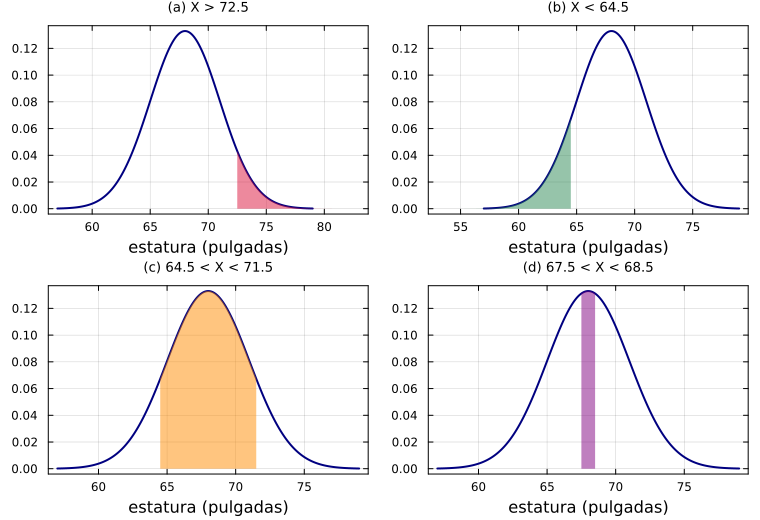

In [12]:
xs = range(57, 79, length = 500)
graf(a, b, t, c) = (p = plot(xs, pdf.(X, xs), lw = 2, color = :navy, legend = false, title = t,
                             xlabel = "estatura (pulgadas)", titlefontsize = 9);
                    sombrear!(p, X, a, b; color = c); p)
plot(graf(72.5, Inf, "(a) X > 72.5", :crimson),
     graf(-Inf, 64.5, "(b) X < 64.5", :seagreen),
     graf(64.5, 71.5, "(c) 64.5 < X < 71.5", :darkorange),
     graf(67.5, 68.5, "(d) 67.5 < X < 68.5", :purple),
     layout = (2, 2), size = (760, 520))

**Respuesta:** (a) 20 (b) 36 (c) 227 (d) 40 estudiantes.

*Nota:* en (b) Julia usa $z = -1.1667$ sin redondear y obtiene $300(0.1217) = 36.5 \approx 37$. Con la tabla ($z = -1.17$) se obtiene $300(0.1210) = 36.3 \approx 36$, que es la respuesta del libro.

---
## Ejercicio 4.81

**Enunciado.** Los diámetros de unos rodamientos (balines) están normalmente distribuidos con media 0.6140 pulgadas y desviación estándar 0.0025 pulgadas. Determinar el porcentaje de rodamientos con diámetros **(a)** entre 0.610 y 0.618 pulgadas inclusive, **(b)** mayores que 0.617 pulgadas, **(c)** menores que 0.608 pulgadas, **(d)** iguales a 0.615 pulgadas.

**Procedimiento.**

Igual que en el ejercicio anterior, los diámetros se registran a la milésima de pulgada más cercana, así que se usa una corrección de $0.0005$. Sea $X \sim N(0.6140,\ 0.0025)$.

**(a)** $0.6095 < X < 0.6185$:
$$z_1 = \frac{0.6095 - 0.6140}{0.0025} = -1.8,\qquad z_2 = \frac{0.6185 - 0.6140}{0.0025} = 1.8$$
$$P = 2\Phi(1.8) - 1 = 2(0.9641) - 1 = 0.9282 \approx 93\%$$

**(b)** $X > 0.6175$:
$$z = \frac{0.6175 - 0.6140}{0.0025} = 1.4 \qquad P(Z > 1.4) = 1 - 0.9192 = 0.0808 \approx 8.1\%$$

**(c)** $X < 0.6075$:
$$z = \frac{0.6075 - 0.6140}{0.0025} = -2.6 \qquad P(Z < -2.6) = 1 - 0.9953 = 0.0047 \approx 0.47\%$$

**(d)** $0.6145 < X < 0.6155$:
$$z_1 = \frac{0.6145 - 0.6140}{0.0025} = 0.2,\qquad z_2 = \frac{0.6155 - 0.6140}{0.0025} = 0.6$$
$$P = \Phi(0.6) - \Phi(0.2) = 0.7257 - 0.5793 = 0.1464 \approx 15\%$$

In [13]:
X = Normal(0.6140, 0.0025)

pa = cdf(X, 0.6185) - cdf(X, 0.6095)
pb = ccdf(X, 0.6175)
pc = cdf(X, 0.6075)
pd = cdf(X, 0.6155) - cdf(X, 0.6145)

for (letra, prob) in zip(["(a)", "(b)", "(c)", "(d)"], [pa, pb, pc, pd])
    println(letra, "  P = ", round(prob, digits = 4), "  →  ", round(100prob, digits = 2), " %")
end

(a)  P = 0.9281  →  92.81 %
(b)  P = 0.0808  →  8.08 %
(c)  P = 0.0047  →  0.47 %
(d)  P = 0.1465  →  14.65 %


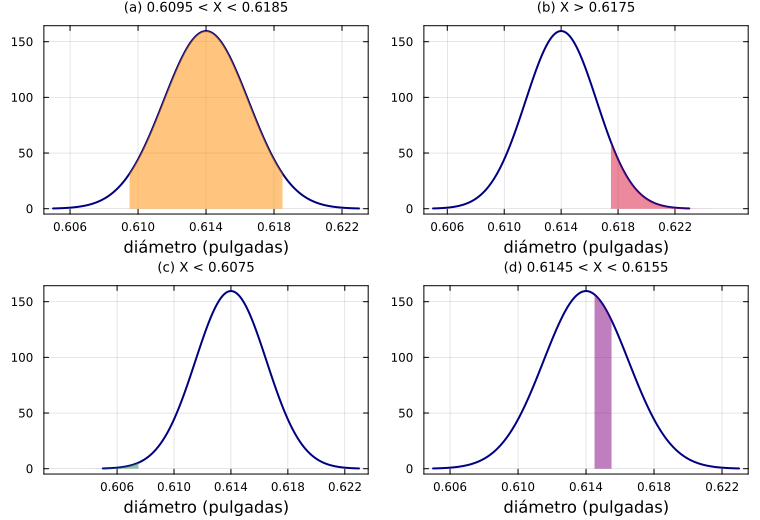

In [14]:
xs = range(0.605, 0.623, length = 500)
graf(a, b, t, c) = (p = plot(xs, pdf.(X, xs), lw = 2, color = :navy, legend = false, title = t,
                             xlabel = "diámetro (pulgadas)", titlefontsize = 9, xticks = 0.606:0.004:0.622);
                    sombrear!(p, X, a, b; color = c); p)
plot(graf(0.6095, 0.6185, "(a) 0.6095 < X < 0.6185", :darkorange),
     graf(0.6175, Inf, "(b) X > 0.6175", :crimson),
     graf(-Inf, 0.6075, "(c) X < 0.6075", :seagreen),
     graf(0.6145, 0.6155, "(d) 0.6145 < X < 0.6155", :purple),
     layout = (2, 2), size = (760, 520))

**Respuesta:** (a) 93 % (b) 8.1 % (c) 0.47 % (d) 15 %

---
## Ejercicio 4.82

**Enunciado.** La nota media de un examen final fue 72 y la desviación estándar 9. El 10 % superior de los estudiantes recibirá A. ¿Cuál es la nota mínima que debe obtener un estudiante para recibir A?

**Procedimiento.**

Sea $X \sim N(72,\ 9)$. Se busca la nota $x$ tal que $P(X > x) = 0.10$, es decir, $\Phi(z) = 0.90$.

En la tabla, el valor más cercano a 0.9000 es $\Phi(1.28) = 0.8997$, luego $z \approx 1.28$ (con más precisión, $z = 1.2816$). Entonces

$$x = \mu + z\,\sigma = 72 + 1.28(9) = 72 + 11.52 = 83.52$$

Como la nota debe superar 83.52, la nota mínima entera para recibir A es **84**.

In [15]:
X = Normal(72, 9)
z = quantile(Normal(0, 1), 0.90)
x = quantile(X, 0.90)
println("z = ", round(z, digits = 4))
println("x = 72 + z·9 = ", round(x, digits = 2), "  →  nota mínima = ", ceil(Int, x))

z = 1.2816
x = 72 + z·9 = 83.53  →  nota mínima = 84


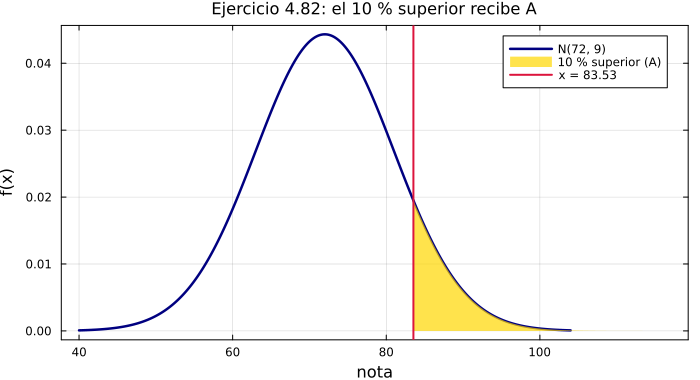

In [16]:
xs = range(40, 104, length = 500)
p = plot(xs, pdf.(X, xs), lw = 2.5, color = :navy, label = "N(72, 9)",
         xlabel = "nota", ylabel = "f(x)", title = "Ejercicio 4.82: el 10 % superior recibe A")
sombrear!(p, X, x, Inf; color = :gold, alpha = 0.7, label = "10 % superior (A)")
vline!([x], color = :crimson, lw = 2, label = "x = $(round(x, digits = 2))")

**Respuesta:** la nota mínima para obtener A es **84**.

---
## Ejercicio 4.83

**Enunciado.** Si un conjunto de medidas está normalmente distribuido, ¿qué porcentaje de ellas difiere de la media **(a)** en más de media desviación estándar, **(b)** en menos de tres cuartos de la desviación estándar?

**Procedimiento.**

Con $Z = (X - \mu)/\sigma$, la condición $|X - \mu| > k\sigma$ equivale a $|Z| > k$. El resultado **no depende** de $\mu$ ni de $\sigma$.

**(a)** $k = 0.5$:
$$P(|Z| > 0.5) = 2\left[1 - \Phi(0.5)\right] = 2(1 - 0.6915) = 2(0.3085) = 0.6170 \approx 61.7\%$$

**(b)** $k = 0.75$:
$$P(|Z| < 0.75) = 2\Phi(0.75) - 1 = 2(0.7734) - 1 = 0.5468 \approx 54.7\%$$

In [17]:
Z = Normal(0, 1)
pa = 2 * ccdf(Z, 0.5)
pb = 2 * cdf(Z, 0.75) - 1
println("(a) P(|Z| > 0.5)  = ", round(pa, digits = 4), "  →  ", round(100pa, digits = 1), " %")
println("(b) P(|Z| < 0.75) = ", round(pb, digits = 4), "  →  ", round(100pb, digits = 1), " %")

(a) P(|Z| > 0.5)  = 0.6171  →  61.7 %
(b) P(|Z| < 0.75) = 0.5467  →  54.7 %


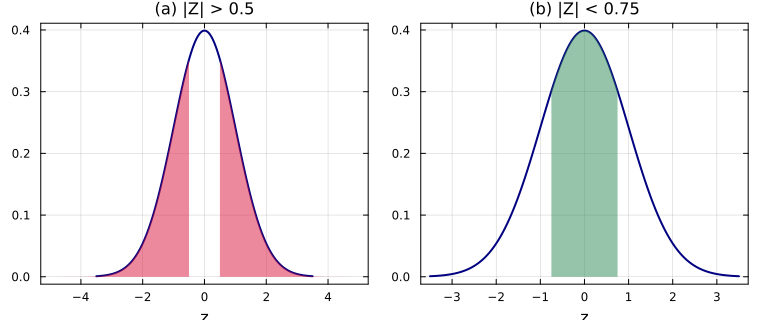

In [18]:
zs = range(-3.5, 3.5, length = 500)
p1 = plot(zs, pdf.(Z, zs), lw = 2, color = :navy, legend = false, title = "(a) |Z| > 0.5", xlabel = "z")
sombrear!(p1, Z, -Inf, -0.5; color = :crimson); sombrear!(p1, Z, 0.5, Inf; color = :crimson)
p2 = plot(zs, pdf.(Z, zs), lw = 2, color = :navy, legend = false, title = "(b) |Z| < 0.75", xlabel = "z")
sombrear!(p2, Z, -0.75, 0.75; color = :seagreen)
plot(p1, p2, layout = (1, 2), size = (760, 320))

**Respuesta:** (a) 61.7 % (b) 54.7 %

---
## Ejercicio 4.92

**Enunciado.** Una bolsa contiene 1 canica roja y 7 blancas. Se extrae una canica, se observa su color, se devuelve a la bolsa y se mezcla bien el contenido. Usando **(a)** la distribución binomial y **(b)** la aproximación de Poisson a la binomial, hallar la probabilidad de que en 8 extracciones se saque una canica roja exactamente 3 veces.

**Procedimiento.**

Como hay reemplazo, las extracciones son independientes y en cada una $p = 1/8$. Sea $X$ el número de rojas en $n = 8$ extracciones.

**(a)** Binomial, $X \sim \text{Bin}(8,\ 1/8)$:
$$P(X = 3) = \binom{8}{3}\left(\frac18\right)^3\left(\frac78\right)^5 = 56 \cdot \frac{7^5}{8^8} = \frac{56 \cdot 16807}{16\,777\,216} = \frac{941\,192}{16\,777\,216} = \frac{117\,649}{2\,097\,152} \approx 0.05610$$

**(b)** Poisson con $\lambda = np = 8 \cdot \frac18 = 1$:
$$P(X = 3) \approx \frac{\lambda^3 e^{-\lambda}}{3!} = \frac{1^3 e^{-1}}{6} = \frac{0.36788}{6} \approx 0.06131$$

Aquí $n = 8$ es pequeño, por eso la aproximación de Poisson no es muy buena: tiene un error de unos 9 %.

In [19]:
B = Binomial(8, 1/8)
P = Poisson(8 * 1/8)

exacta = binomial(8, 3) * (1//8)^3 * (7//8)^5
println("(a) Binomial: P(X = 3) = ", exacta, " ≈ ", round(pdf(B, 3), digits = 5))
println("(b) Poisson : P(X = 3) = e⁻¹/3! ≈ ", round(pdf(P, 3), digits = 5))
println("Error relativo de la aproximación: ", round(100 * abs(pdf(P, 3) - pdf(B, 3)) / pdf(B, 3), digits = 1), " %")

(a) Binomial: P(X = 3) = 117649

//2097152 ≈ 0.0561
(b) Poisson : P(X = 3) = e⁻¹/3! ≈ 0.06131
Error relativo de la aproximación: 9.3 %


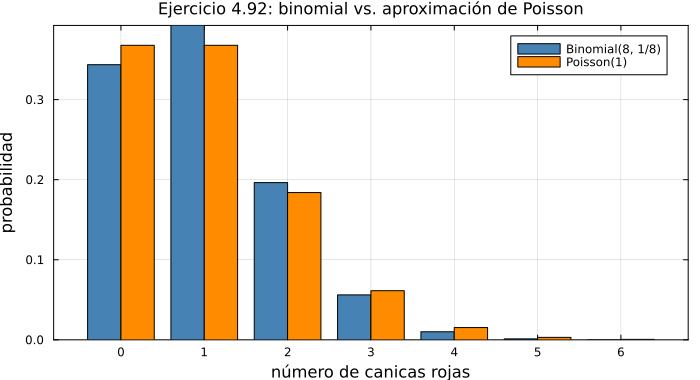

In [20]:
k = 0:6
bar(k .- 0.2, pdf.(B, k), bar_width = 0.4, color = :steelblue, label = "Binomial(8, 1/8)")
bar!(k .+ 0.2, pdf.(P, k), bar_width = 0.4, color = :darkorange, label = "Poisson(1)",
     xticks = k, xlabel = "número de canicas rojas", ylabel = "probabilidad",
     title = "Ejercicio 4.92: binomial vs. aproximación de Poisson")

**Respuesta:** (a) $0.05610$ (b) $0.06131$

---
## Ejercicio 4.99

**Enunciado.** Si se eligen al azar 13 cartas (sin reemplazo) de una baraja ordinaria de 52 cartas, hallar la probabilidad de que **(a)** 6 sean figuras, **(b)** ninguna sea figura.

**Procedimiento.**

Como se extrae sin reemplazo, el número $X$ de figuras sigue una distribución **hipergeométrica**:

$$P(X = x) = \frac{\binom{b}{x}\binom{N-b}{n-x}}{\binom{N}{n}}$$

con $N = 52$ cartas, $n = 13$ extraídas y $b$ figuras en la baraja. En una baraja inglesa las figuras son J, Q y K de cada uno de los 4 palos, así que $b = 12$ y hay $40$ cartas que no son figura.

**(a)** $$P(X = 6) = \frac{\binom{12}{6}\binom{40}{7}}{\binom{52}{13}}$$

**(b)** $$P(X = 0) = \frac{\binom{12}{0}\binom{40}{13}}{\binom{52}{13}}$$

> **Nota:** la respuesta del libro está escrita como $\binom{13}{6}\binom{39}{7}/\binom{52}{13}$ y $\binom{13}{0}\binom{39}{13}/\binom{52}{13}$, es decir, considera 13 figuras y 39 no figuras. A continuación se calculan ambas versiones.

In [21]:
N, n = 52, 13

for b in (12, 13)
    H = Hypergeometric(b, N - b, n)        # (éxitos, fracasos, extracciones)
    pa = binomial(big(b), 6) * binomial(big(N - b), 7) // binomial(big(N), n)
    pb = binomial(big(N - b), 13) // binomial(big(N), n)
    println("Con b = $b figuras:")
    println("   (a) P(X = 6) = ", round(Float64(pa), digits = 5), "   (Distributions: ", round(pdf(H, 6), digits = 5), ")")
    println("   (b) P(X = 0) = ", round(Float64(pb), digits = 5), "   (Distributions: ", round(pdf(H, 0), digits = 5), ")")
end

Con b = 12 figuras:


   (a) P(X = 6) = 0.02713   (Distributions: 0.02713)
   (b) P(X = 0) = 0.01895   (Distributions: 0.01895)
Con b = 13 figuras:
   (a) P(X = 6) = 0.04156   (Distributions: 0.04156)
   (b) P(X = 0) = 0.01279   (Distributions: 0.01279)


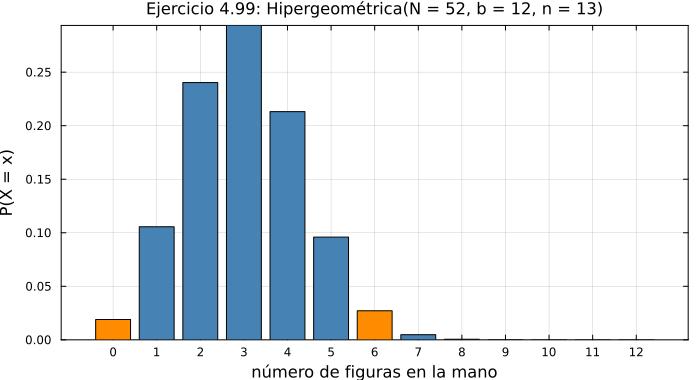

In [22]:
H = Hypergeometric(12, 40, 13)
colores = [x in (0, 6) ? :darkorange : :steelblue for x in 0:12]
bar(0:12, pdf.(H, 0:12), color = colores, legend = false, xticks = 0:12,
    xlabel = "número de figuras en la mano", ylabel = "P(X = x)",
    title = "Ejercicio 4.99: Hipergeométrica(N = 52, b = 12, n = 13)")

**Respuesta (con 12 figuras):**

(a) $\dfrac{\binom{12}{6}\binom{40}{7}}{\binom{52}{13}} \approx 0.0271$ (b) $\dfrac{\binom{40}{13}}{\binom{52}{13}} \approx 0.0190$

Con la convención del libro (13 figuras): (a) $\approx 0.0416$ (b) $\approx 0.0128$.

---
## Ejercicio 4.102

**Enunciado.** Hallar **(a)** el tercer y **(b)** el cuarto momento respecto a la media de una distribución uniforme.

**Procedimiento.**

Si $X \sim U(a, b)$, su densidad es $f(x) = \dfrac{1}{b-a}$ para $a \le x \le b$ y su media es $\mu = \dfrac{a+b}{2}$.

El momento $r$-ésimo respecto a la media es $\mu_r = E\left[(X-\mu)^r\right] = \dfrac{1}{b-a}\displaystyle\int_a^b (x-\mu)^r\,dx$.

Con el cambio $u = x - \mu$ y $h = \dfrac{b-a}{2}$, los límites quedan $u \in [-h,\ h]$ y $b - a = 2h$:

$$\mu_r = \frac{1}{2h}\int_{-h}^{h} u^r\,du$$

**(a)** $r = 3$: el integrando $u^3$ es impar y el intervalo es simétrico, así que
$$\mu_3 = \frac{1}{2h}\left[\frac{u^4}{4}\right]_{-h}^{h} = \frac{1}{2h}\left(\frac{h^4}{4} - \frac{h^4}{4}\right) = 0$$

**(b)** $r = 4$:
$$\mu_4 = \frac{1}{2h}\left[\frac{u^5}{5}\right]_{-h}^{h} = \frac{1}{2h}\cdot\frac{2h^5}{5} = \frac{h^4}{5} = \frac{1}{5}\left(\frac{b-a}{2}\right)^4 = \frac{(b-a)^4}{80}$$

In [23]:
# Verificación numérica con un ejemplo: a = 2, b = 7
a, b = 2.0, 7.0
U = Uniform(a, b)
μ = mean(U)

# Integración numérica por la regla del punto medio
m = 1_000_000
Δ = (b - a) / m
xs = a .+ Δ .* ((1:m) .- 0.5)
μ3 = sum((xs .- μ).^3) * Δ / (b - a)
μ4 = sum((xs .- μ).^4) * Δ / (b - a)

println("(a) μ₃ numérico = ", round(μ3, digits = 6), "     fórmula: 0")
println("(b) μ₄ numérico = ", round(μ4, digits = 6), "   fórmula (b-a)⁴/80 = ", (b - a)^4 / 80)

(a) μ₃ numérico = 0.0

     fórmula: 0
(b) μ₄ numérico = 7.8125   fórmula (b-a)⁴/80 = 7.8125


**Respuesta:** (a) $\mu_3 = 0$ (b) $\mu_4 = \dfrac{(b-a)^4}{80}$

---
## Ejercicio 4.103

**Enunciado.** Determinar el coeficiente de **(a)** asimetría y **(b)** curtosis de una distribución uniforme.

**Procedimiento.**

Para $X \sim U(a,b)$ la varianza es $\sigma^2 = \dfrac{(b-a)^2}{12}$, y del ejercicio 4.102, $\mu_3 = 0$ y $\mu_4 = \dfrac{(b-a)^4}{80}$.

**(a)** Coeficiente de asimetría:
$$\alpha_3 = \frac{\mu_3}{\sigma^3} = \frac{0}{\sigma^3} = 0$$
Es lógico, porque la densidad uniforme es simétrica respecto a su media.

**(b)** Coeficiente de curtosis:
$$\alpha_4 = \frac{\mu_4}{\sigma^4} = \frac{(b-a)^4/80}{\left[(b-a)^2/12\right]^2} = \frac{(b-a)^4}{80}\cdot\frac{144}{(b-a)^4} = \frac{144}{80} = \frac{9}{5} = 1.8$$

Como $1.8 < 3$ (el valor de la normal), la distribución uniforme es **platicúrtica**: es más "plana" que la normal.

In [24]:
U = Uniform(2, 7)
println("(a) Asimetría = ", skewness(U))
# Distributions.kurtosis devuelve el EXCESO de curtosis (α₄ − 3)
println("(b) Curtosis α₄ = kurtosis + 3 = ", kurtosis(U), " + 3 = ", kurtosis(U) + 3, "  = 9/5")

(a) Asimetría = 0.0
(b) Curtosis α₄ = kurtosis + 3 = -1.2 + 3 = 1.8  = 9/5


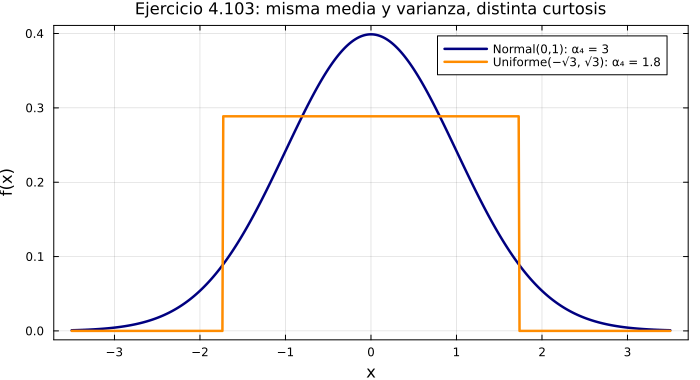

In [25]:
U0 = Uniform(-sqrt(3), sqrt(3))        # uniforme con media 0 y varianza 1
xs = range(-3.5, 3.5, length = 700)
plot(xs, pdf.(Normal(0, 1), xs), lw = 2.5, color = :navy, label = "Normal(0,1): α₄ = 3")
plot!(xs, pdf.(U0, xs), lw = 2.5, color = :darkorange, label = "Uniforme(−√3, √3): α₄ = 1.8",
      xlabel = "x", ylabel = "f(x)", title = "Ejercicio 4.103: misma media y varianza, distinta curtosis")

**Respuesta:** (a) $\alpha_3 = 0$ (b) $\alpha_4 = 9/5 = 1.8$

---
## Ejercicio 4.104

**Enunciado.** Si $X$ e $Y$ son independientes y ambas están uniformemente distribuidas en el intervalo de 0 a 1, hallar $P\left(|X - Y| \ge \tfrac12\right)$.

**Procedimiento.**

Por independencia, la densidad conjunta es $f(x,y) = 1$ en el cuadrado unitario $[0,1]\times[0,1]$, así que la probabilidad de un evento es igual a su **área** dentro del cuadrado.

$$|X - Y| \ge \tfrac12 \iff Y \le X - \tfrac12 \quad\text{o}\quad Y \ge X + \tfrac12$$

Cada una de estas regiones es un triángulo rectángulo con catetos de longitud $\tfrac12$:

* $Y \le X - \tfrac12$: vértices $(\tfrac12, 0),\ (1, 0),\ (1, \tfrac12)$, con área $\tfrac12\cdot\tfrac12\cdot\tfrac12 = \tfrac18$.
* $Y \ge X + \tfrac12$: vértices $(0, \tfrac12),\ (0, 1),\ (\tfrac12, 1)$, con área $\tfrac18$.

$$P\left(|X - Y| \ge \tfrac12\right) = \frac18 + \frac18 = \frac14$$

La simulación de Monte Carlo de abajo comprueba el resultado.

In [26]:
Random.seed!(2429893)
M = 1_000_000
x = rand(M); y = rand(M)
estimacion = mean(abs.(x .- y) .>= 0.5)
println("Valor exacto           : 1/4 = 0.25")
println("Simulación (M = 10⁶)   : ", round(estimacion, digits = 4))

Valor exacto           : 1/4 = 0.25


Simulación (M = 10⁶)   : 0.2501


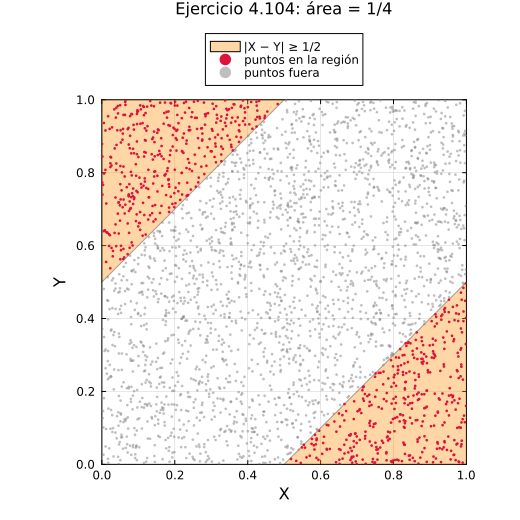

In [27]:
k = 3000
dentro = abs.(x[1:k] .- y[1:k]) .>= 0.5
p = plot(Shape([0.5, 1, 1], [0, 0, 0.5]), color = :darkorange, alpha = 0.35, label = "|X − Y| ≥ 1/2")
plot!(Shape([0, 0, 0.5], [0.5, 1, 1]), color = :darkorange, alpha = 0.35, label = "")
scatter!(x[1:k][dentro], y[1:k][dentro], ms = 1.5, msw = 0, color = :crimson, label = "puntos en la región")
scatter!(x[1:k][.!dentro], y[1:k][.!dentro], ms = 1.5, msw = 0, color = :gray, alpha = 0.5, label = "puntos fuera")
plot!(xlims = (0, 1), ylims = (0, 1), aspect_ratio = 1, size = (520, 520), legend = :outertop,
      xlabel = "X", ylabel = "Y", title = "Ejercicio 4.104: área = 1/4")

**Respuesta:** $P\left(|X - Y| \ge \tfrac12\right) = \dfrac14$

---
## Ejercicio 4.109

**Enunciado.** Para una distribución ji-cuadrado con 12 grados de libertad, hallar el valor de $\chi^2_c$ tal que **(a)** el área a la derecha de $\chi^2_c$ sea 0.05, **(b)** el área a la izquierda de $\chi^2_c$ sea 0.99, **(c)** el área a la derecha de $\chi^2_c$ sea 0.025.

**Procedimiento.**

Sea $U \sim \chi^2(12)$. Se buscan percentiles, es decir, valores con un área acumulada a la izquierda dada:

**(a)** Área a la derecha 0.05, o sea área a la izquierda 0.95: $\chi^2_c = \chi^2_{0.95}(12)$. En la tabla del apéndice, $\chi^2_c = 21.0$.

**(b)** Área a la izquierda 0.99: $\chi^2_c = \chi^2_{0.99}(12) = 26.2$.

**(c)** Área a la derecha 0.025, o sea área a la izquierda 0.975: $\chi^2_c = \chi^2_{0.975}(12) = 23.3$.

En Julia esto se calcula con la función cuantil `quantile(Chisq(12), p)`.

In [28]:
U = Chisq(12)
ca = quantile(U, 0.95)
cb = quantile(U, 0.99)
cc = quantile(U, 0.975)
println("(a) χ²c = ", round(ca, digits = 2), "   (comprobación: área derecha = ", round(ccdf(U, ca), digits = 3), ")")
println("(b) χ²c = ", round(cb, digits = 2), "   (comprobación: área izquierda = ", round(cdf(U, cb), digits = 3), ")")
println("(c) χ²c = ", round(cc, digits = 2), "   (comprobación: área derecha = ", round(ccdf(U, cc), digits = 3), ")")

(a) χ²c = 21.03

   (comprobación: área derecha = 0.05)
(b) χ²c = 26.22   (comprobación: área izquierda = 0.99)
(c) χ²c = 23.34   (comprobación: área derecha = 0.025)


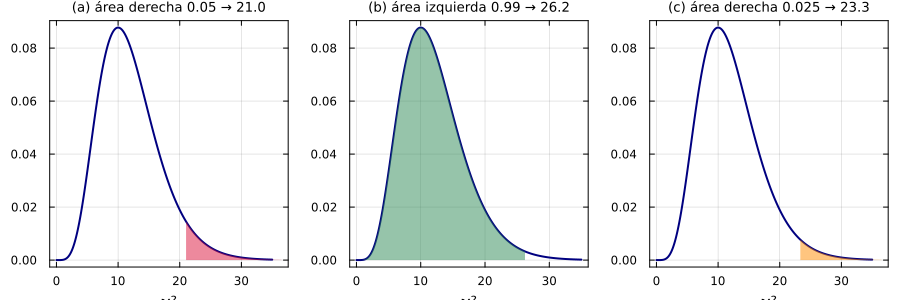

In [29]:
xs = range(0, 35, length = 600)
graf(a, b, c, t) = (p = plot(xs, pdf.(U, xs), lw = 2, color = :navy, legend = false, title = t,
                             xlabel = "χ²", titlefontsize = 9); sombrear!(p, U, a, b; color = c); p)
plot(graf(ca, Inf, :crimson, "(a) área derecha 0.05 → $(round(ca, digits = 1))"),
     graf(0, cb, :seagreen, "(b) área izquierda 0.99 → $(round(cb, digits = 1))"),
     graf(cc, Inf, :darkorange, "(c) área derecha 0.025 → $(round(cc, digits = 1))"),
     layout = (1, 3), size = (900, 300))

**Respuesta:** (a) $21.0$ (b) $26.2$ (c) $23.3$

---
## Ejercicio 4.117

**Enunciado.** Hallar los valores de $t$ para los cuales el área de la cola derecha de la distribución $t$ de Student es 0.01, si el número de grados de libertad $\nu$ es igual a **(a)** 4, **(b)** 12, **(c)** 25, **(d)** 60, **(e)** 150.

**Procedimiento.**

Si el área a la derecha es 0.01, el área a la izquierda es 0.99, así que se busca el percentil $t_{0.99}(\nu)$. En la tabla de la $t$:

| $\nu$ | 4 | 12 | 25 | 60 | 150 |
|:-:|:-:|:-:|:-:|:-:|:-:|
| $t_{0.99}$ | 3.75 | 2.68 | 2.48 | 2.39 | 2.33 |

Para $\nu$ grande (la tabla del libro llega hasta 120 y luego pone $\infty$), la $t$ se aproxima a la normal estándar. Por eso para $\nu = 150$ el libro usa $z_{0.99} = 2.33$. El valor exacto, calculado abajo en Julia, es $2.35$.

In [30]:
for ν in (4, 12, 25, 60, 150)
    t = quantile(TDist(ν), 0.99)
    println("ν = ", lpad(ν, 3), "   t₀.₉₉ = ", round(t, digits = 3))
end
println("Normal estándar: z₀.₉₉ = ", round(quantile(Normal(0, 1), 0.99), digits = 3))

ν =   4

   t₀.₉₉ = 3.747
ν =  12   t₀.₉₉ = 2.681
ν =  25   t₀.₉₉ = 2.485
ν =  60   t₀.₉₉ = 2.39
ν = 150   t₀.₉₉ = 2.351
Normal estándar: z₀.₉₉ = 2.326


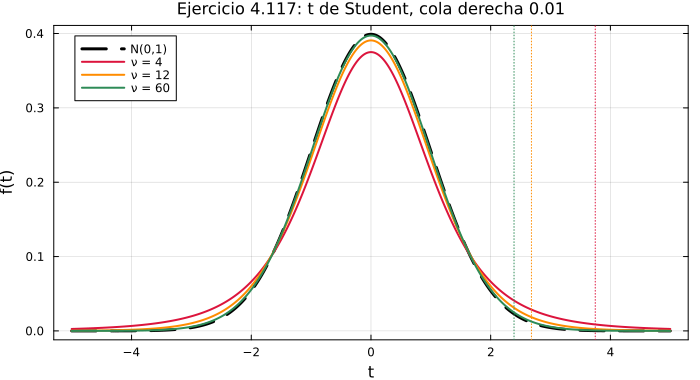

In [31]:
ts = range(-5, 5, length = 600)
p = plot(ts, pdf.(Normal(0, 1), ts), lw = 3, color = :black, ls = :dash, label = "N(0,1)",
         xlabel = "t", ylabel = "f(t)", title = "Ejercicio 4.117: t de Student, cola derecha 0.01")
for (ν, c) in zip((4, 12, 60), (:crimson, :darkorange, :seagreen))
    plot!(p, ts, pdf.(TDist(ν), ts), lw = 2, color = c, label = "ν = $ν")
    vline!(p, [quantile(TDist(ν), 0.99)], color = c, ls = :dot, label = "")
end
p

**Respuesta:** (a) 3.75 (b) 2.68 (c) 2.48 (d) 2.39 (e) 2.33 según el libro (aproximación normal); el valor exacto con 150 grados de libertad es 2.35.

---
*Fin de la tarea.*